# Adapted company representation evaluation

This notebook visualizes whether observed destinations are organized near their OOD source companies in the company-representation spaces. The evaluation uses empirical transition shares as relevance weights and 49 hard semantic non-destinations per source.

The most direct ranking metrics are **transition-weighted NDCG@K** and **weighted pairwise accuracy**. A value above competing representations means the observed destinations are ranked more effectively against the same negatives.

In [1]:
from pathlib import Path

# Editable settings
ROOT = Path.cwd()
if not (ROOT / 'test_adapted_company_representations.py').exists():
    ROOT = Path('/home/leeze/career_experiments_2')
RESULT_DIR = ROOT / 'data' / 'adapted_company_representation_test'
PRIMARY_K = 10
TOP_COMPANIES_TO_SHOW = 15

REPRESENTATIONS = ('raw_factual', 'none_id', 'kar_base', 'kar_ours')
DISPLAY_NAMES = {
    'raw_factual': 'Raw factual',
    'none_id': 'DIN None ID',
    'kar_base': 'KAR-Base HEA',
    'kar_ours': 'KAR-Ours HEA',
}
COLORS = {
    'raw_factual': '#9467bd',
    'none_id': '#7f7f7f',
    'kar_base': '#2878b5',
    'kar_ours': '#d62728',
}

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

paths = {
    'detail': RESULT_DIR / 'company_representation_per_source.csv',
    'summary': RESULT_DIR / 'company_representation_summary.csv',
    'paired': RESULT_DIR / 'company_representation_paired_tests.csv',
}
missing = [path for path in paths.values() if not path.exists()]
if missing:
    formatted = '\n'.join(f'  - {path}' for path in missing)
    raise FileNotFoundError(
        'Representation-test outputs are missing. Run '
        '`python test_adapted_company_representations.py` first.\n' + formatted
    )

detail = pd.read_csv(paths['detail'])
summary = pd.read_csv(paths['summary'])
paired = pd.read_csv(paths['paired'])
expected = set(REPRESENTATIONS)
for name, frame in [('detail', detail), ('summary', summary)]:
    present = set(frame['representation'])
    if present != expected:
        raise ValueError(f'{name} representations differ: expected {expected}, got {present}')

source_counts = detail.groupby('representation')['source_company'].nunique()
print(f'Per-source rows: {len(detail):,}')
print(f'OOD source companies: {source_counts.iloc[0]:,}')
print(f'Total observed transitions: {detail.groupby("source_company")["transition_count"].first().sum():,}')
display(source_counts.rename('source_company_count').to_frame())

Per-source rows: 2,044
OOD source companies: 511
Total observed transitions: 1,869


,source_company_count
representation,
kar_base,511
kar_ours,511
none_id,511
raw_factual,511


## Overall metric table

`macro_mean` gives every OOD source company equal weight. `transition_weighted_mean` gives more influence to sources supported by more observed transitions. The confidence interval is a source-company bootstrap interval for the macro mean.

In [3]:
display_metrics = [
    f'ndcg_at_{PRIMARY_K}',
    'weighted_pairwise_accuracy',
    'weighted_similarity_margin',
]
summary_table = (
    summary[summary.metric.isin(display_metrics)]
    .assign(representation=lambda x: x.representation.map(DISPLAY_NAMES))
    .pivot(index='representation', columns='metric', values=[
        'macro_mean', 'transition_weighted_mean',
        'macro_mean_ci95_lower', 'macro_mean_ci95_upper',
    ])
)
display(summary_table.round(5))

macro_mean                             \
metric         ndcg_at_10 weighted_pairwise_accuracy   
representation                                         
DIN None ID       0.17883                    0.50142   
KAR-Base HEA      0.07155                    0.34496   
KAR-Ours HEA      0.03217                    0.18028   
Raw factual       0.03657                    0.07663   

                                          transition_weighted_mean  \
metric         weighted_similarity_margin               ndcg_at_10   
representation                                                       
DIN None ID                      -0.00021                  0.25973   
KAR-Base HEA                     -0.00915                  0.08616   
KAR-Ours HEA                     -0.39842                  0.06105   
Raw factual                      -0.16097                  0.05763   

                                                                      \
metric         weighted_pairwise_accuracy weighted_similarity_margin   
representation                                                         
DIN None ID                       0.51170                    0.00622   
KAR-Base HEA                      0.30789                   -0.01204   
KAR-Ours HEA                      0.18090                   -0.41483   
Raw factual                       0.07326                   -0.16648   

               macro_mean_ci95_lower                             \
metric                    ndcg_at_10 weighted_pairwise_accuracy   
representation                                                    
DIN None ID                  0.15714                    0.47642   
KAR-Base HEA                 0.05930                    0.32170   
KAR-Ours HEA                 0.02309                    0.16093   
Raw factual                  0.02603                    0.06041   

                                          macro_mean_ci95_upper  \
metric         weighted_similarity_margin            ndcg_at_10   
representation                                                    
DIN None ID                      -0.01423               0.20297   
KAR-Base HEA                     -0.01081               0.08459   
KAR-Ours HEA                     -0.42977               0.04180   
Raw factual                      -0.16955               0.04844   

                                                                      
metric         weighted_pairwise_accuracy weighted_similarity_margin  
representation                                                        
DIN None ID                       0.52516                    0.01374  
KAR-Base HEA                      0.36901                   -0.00755  
KAR-Ours HEA                      0.19987                   -0.36972  
Raw factual                       0.09401                   -0.15284

## Transition-weighted NDCG across cutoffs

Higher is better. The shaded region is the 95% source-bootstrap confidence interval around the macro mean.

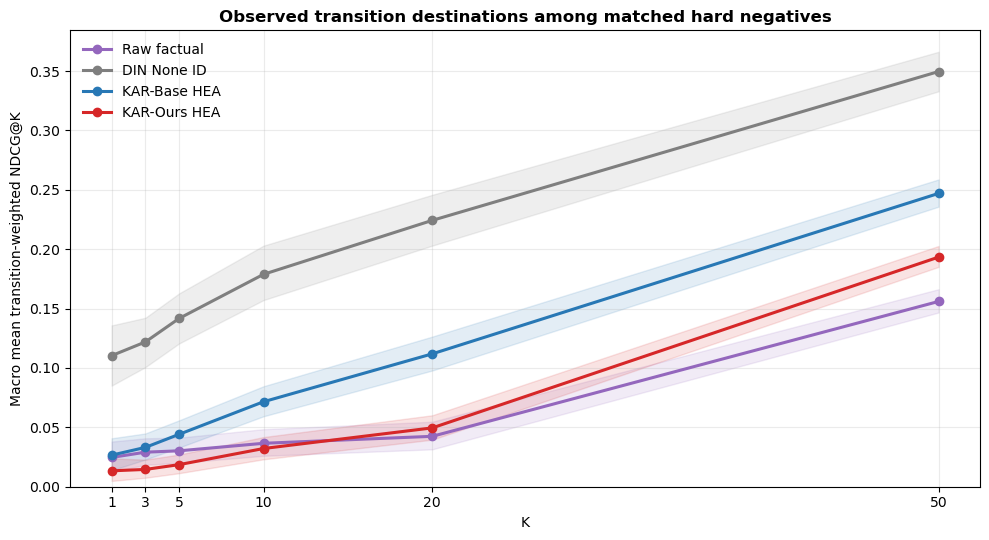

In [4]:
ndcg_summary = summary[summary.metric.str.match(r'^ndcg_at_\d+$')].copy()
ndcg_summary['k'] = ndcg_summary.metric.str.extract(r'(\d+)$').astype(int)
ks = sorted(ndcg_summary.k.unique())
fig, axis = plt.subplots(figsize=(10, 5.5))
for representation in REPRESENTATIONS:
    values = ndcg_summary[ndcg_summary.representation == representation].sort_values('k')
    axis.plot(
        values.k, values.macro_mean, marker='o', linewidth=2.2,
        color=COLORS[representation], label=DISPLAY_NAMES[representation]
    )
    axis.fill_between(
        values.k, values.macro_mean_ci95_lower, values.macro_mean_ci95_upper,
        color=COLORS[representation], alpha=0.13
    )
axis.set_xticks(ks)
axis.set_xlabel('K')
axis.set_ylabel('Macro mean transition-weighted NDCG@K')
axis.set_ylim(bottom=0)
axis.grid(alpha=0.25)
axis.legend(frameon=False)
axis.set_title('Observed transition destinations among matched hard negatives', fontweight='bold')
fig.tight_layout()
plt.show()

## Pairwise ranking and similarity margin

Weighted pairwise accuracy is the transition-share-weighted probability that an observed destination has greater cosine similarity to the source than a hard negative. The similarity margin is weighted destination similarity minus mean hard-negative similarity. Higher is better for both. Diamonds show transition-count-weighted means.

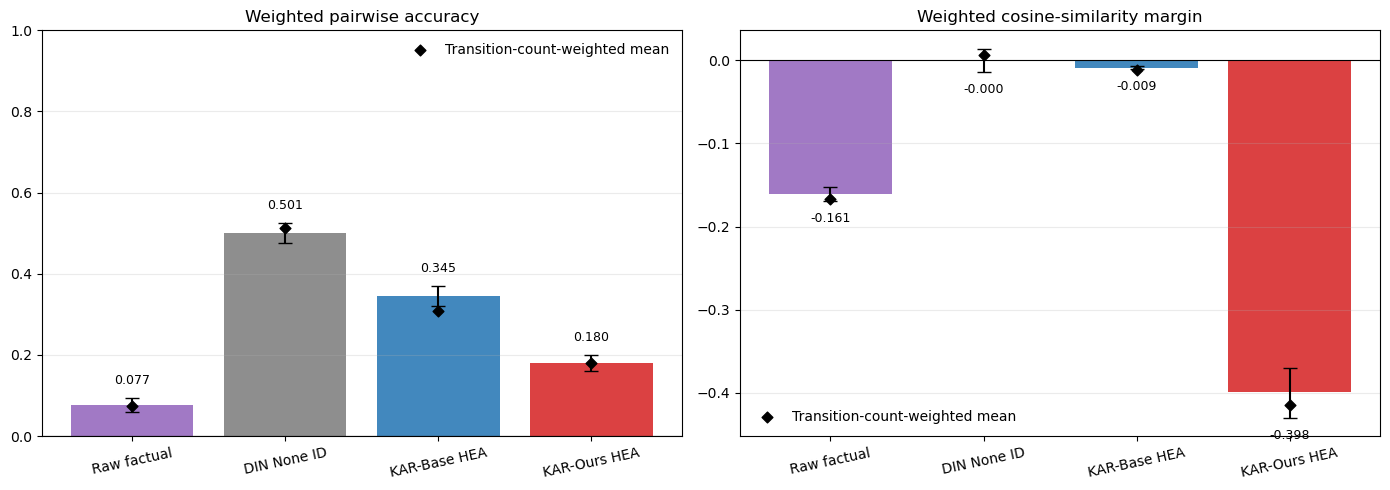

In [5]:
bar_metrics = [
    ('weighted_pairwise_accuracy', 'Weighted pairwise accuracy'),
    ('weighted_similarity_margin', 'Weighted cosine-similarity margin'),
]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(REPRESENTATIONS))
for axis, (metric, title) in zip(axes, bar_metrics):
    values = (
        summary[summary.metric == metric]
        .set_index('representation').reindex(REPRESENTATIONS)
    )
    means = values.macro_mean.to_numpy()
    errors = np.vstack([
        means - values.macro_mean_ci95_lower.to_numpy(),
        values.macro_mean_ci95_upper.to_numpy() - means,
    ])
    bars = axis.bar(
        x, means, yerr=errors, capsize=5,
        color=[COLORS[name] for name in REPRESENTATIONS], alpha=0.88
    )
    axis.scatter(
        x, values.transition_weighted_mean, marker='D', color='black', s=30,
        label='Transition-count-weighted mean', zorder=3
    )
    axis.bar_label(bars, fmt='%.3f', padding=8, fontsize=9)
    axis.axhline(0, color='black', linewidth=0.8)
    axis.set_xticks(x, [DISPLAY_NAMES[name] for name in REPRESENTATIONS], rotation=12)
    axis.set_title(title)
    axis.grid(axis='y', alpha=0.25)
    axis.legend(frameon=False)
axes[0].set_ylim(0, 1)
fig.tight_layout()
plt.show()

## Per-source distributions

These distributions reveal whether an aggregate difference is broadly shared or caused by a small set of source companies. Outliers are hidden from the box plots for readability but remain included in all metrics.

/home/leeze/.tmp/ipykernel_1010742/3873012234.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plot = axis.boxplot(
/home/leeze/.tmp/ipykernel_1010742/3873012234.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plot = axis.boxplot(
/home/leeze/.tmp/ipykernel_1010742/3873012234.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plot = axis.boxplot(


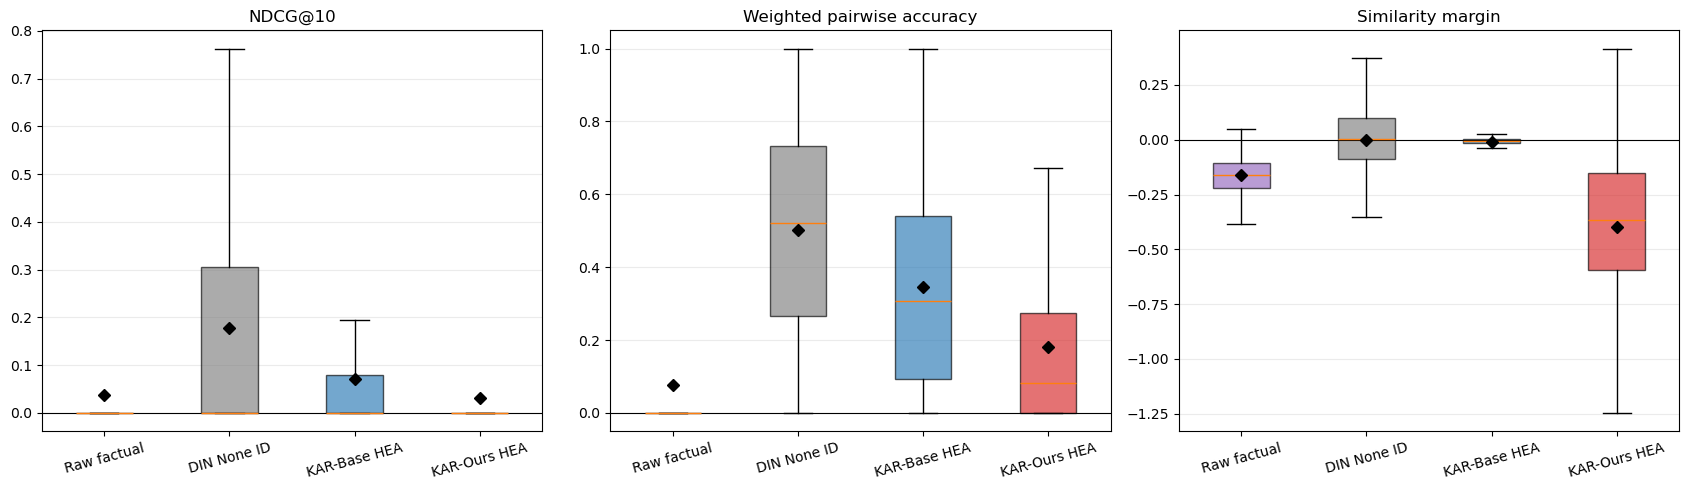

In [6]:
distribution_metrics = [
    (f'ndcg_at_{PRIMARY_K}', f'NDCG@{PRIMARY_K}'),
    ('weighted_pairwise_accuracy', 'Weighted pairwise accuracy'),
    ('weighted_similarity_margin', 'Similarity margin'),
]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for axis, (metric, title) in zip(axes, distribution_metrics):
    arrays = [
        detail.loc[detail.representation == representation, metric].dropna().to_numpy()
        for representation in REPRESENTATIONS
    ]
    plot = axis.boxplot(
        arrays, labels=[DISPLAY_NAMES[name] for name in REPRESENTATIONS],
        patch_artist=True, showfliers=False, showmeans=True,
        meanprops={'marker': 'D', 'markerfacecolor': 'black', 'markeredgecolor': 'black'}
    )
    for patch, representation in zip(plot['boxes'], REPRESENTATIONS):
        patch.set_facecolor(COLORS[representation])
        patch.set_alpha(0.65)
    axis.axhline(0, color='black', linewidth=0.8)
    axis.tick_params(axis='x', rotation=15)
    axis.set_title(title)
    axis.grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()

## Paired KAR-Ours comparisons

All differences compare the same OOD source companies and matched negatives. Positive values favor KAR-Ours. The reported p-value comes from the test script's two-sided paired sign-permutation test.

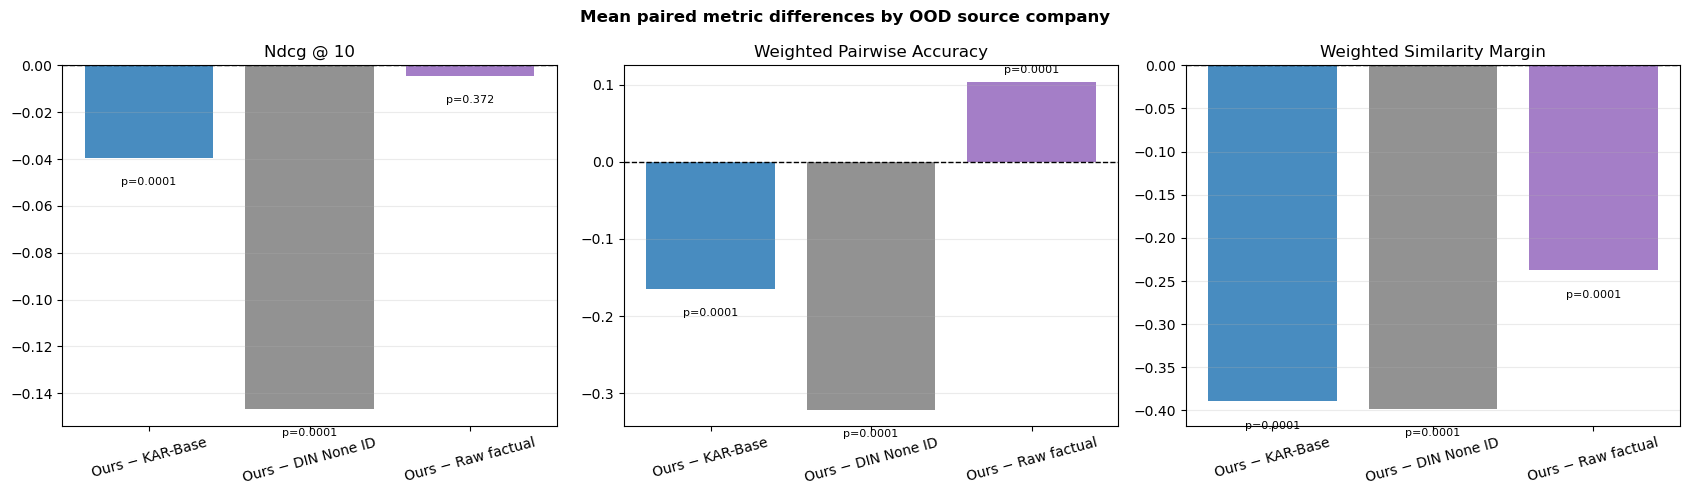

,,paired_source_count,mean_difference,median_difference,fraction_kar_ours_higher,two_sided_sign_permutation_p_value
metric,comparison,,,,,
ndcg_at_10,kar_ours - kar_base,511,-0.03939,0.00000,0.07632,0.00010
weighted_pairwise_accuracy,kar_ours - kar_base,511,-0.16468,-0.11224,0.18982,0.00010
weighted_similarity_margin,kar_ours - kar_base,511,-0.38927,-0.35652,0.10176,0.00010
ndcg_at_10,kar_ours - none_id,511,-0.14666,0.00000,0.07828,0.00010
weighted_pairwise_accuracy,kar_ours - none_id,511,-0.32115,-0.31354,0.15656,0.00010
weighted_similarity_margin,kar_ours - none_id,511,-0.39821,-0.37582,0.14677,0.00010
ndcg_at_10,kar_ours - raw_factual,511,-0.00440,0.00000,0.08611,0.37156
weighted_pairwise_accuracy,kar_ours - raw_factual,511,0.10365,0.04082,0.63209,0.00010
weighted_similarity_margin,kar_ours - raw_factual,511,-0.23745,-0.20221,0.19178,0.00010


In [7]:
comparison_order = ('kar_ours - kar_base', 'kar_ours - none_id', 'kar_ours - raw_factual')
comparison_labels = {
    'kar_ours - kar_base': 'Ours − KAR-Base',
    'kar_ours - none_id': 'Ours − DIN None ID',
    'kar_ours - raw_factual': 'Ours − Raw factual',
}
selected_metrics = [f'ndcg_at_{PRIMARY_K}', 'weighted_pairwise_accuracy', 'weighted_similarity_margin']
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for axis, metric in zip(axes, selected_metrics):
    values = paired[paired.metric == metric].set_index('comparison').reindex(comparison_order)
    bars = axis.bar(
        np.arange(len(comparison_order)), values.mean_difference,
        color=['#2878b5', '#7f7f7f', '#9467bd'], alpha=0.85
    )
    axis.axhline(0, color='black', linestyle='--', linewidth=1)
    axis.set_xticks(
        np.arange(len(comparison_order)),
        [comparison_labels[name] for name in comparison_order], rotation=15
    )
    axis.set_title(metric.replace('_', ' ').replace('at', '@').title())
    axis.grid(axis='y', alpha=0.25)
    for bar, p_value in zip(bars, values.two_sided_sign_permutation_p_value):
        height = bar.get_height()
        axis.annotate(
            f'p={p_value:.3g}',
            (bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5 if height >= 0 else -14), textcoords='offset points',
            ha='center', va='bottom' if height >= 0 else 'top', fontsize=8
        )
fig.suptitle('Mean paired metric differences by OOD source company', fontweight='bold')
fig.tight_layout()
plt.show()
display(
    paired[paired.metric.isin(selected_metrics)]
    .set_index(['metric', 'comparison'])
    .round(5)
)

## Performance by transition evidence

Companies with only one observed transition have noisy relevance labels. This plot bins sources by transition count and shows whether the conclusion persists for better-supported sources.

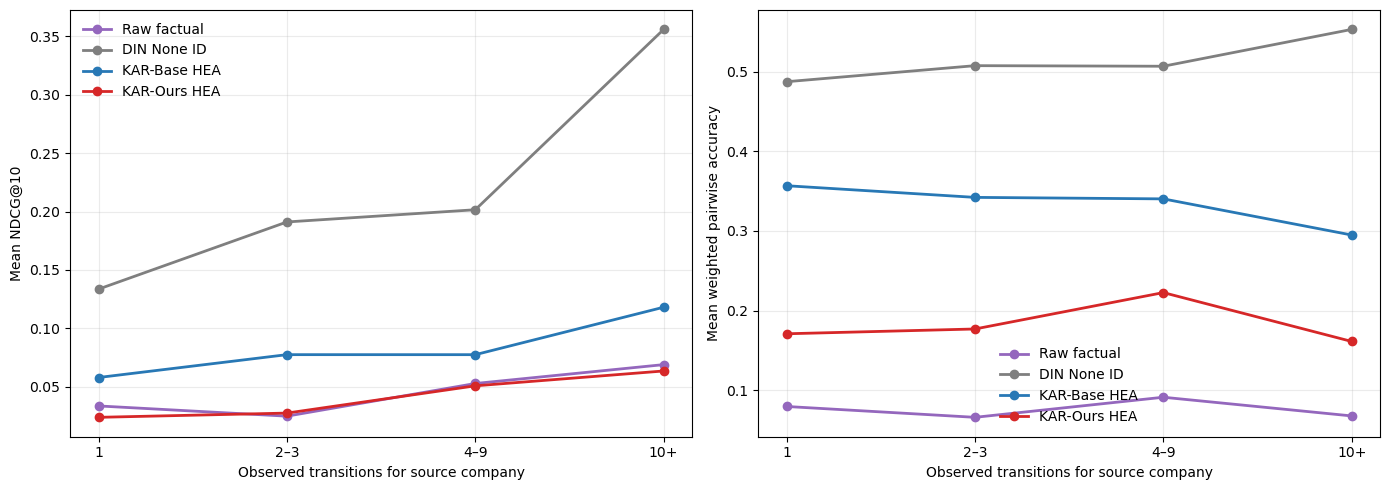

representation,kar_base,kar_ours,none_id,raw_factual
transition_bucket,,,,
1,235,235,235,235
2–3,157,157,157,157
4–9,80,80,80,80
10+,39,39,39,39


In [8]:
def transition_bucket(count):
    if count == 1:
        return '1'
    if count <= 3:
        return '2–3'
    if count <= 9:
        return '4–9'
    return '10+'

bucket_order = ['1', '2–3', '4–9', '10+']
detail['transition_bucket'] = pd.Categorical(
    detail.transition_count.map(transition_bucket), categories=bucket_order, ordered=True
)
bucketed = (
    detail.groupby(['representation', 'transition_bucket'], observed=True)
    .agg(
        source_count=('source_company', 'nunique'),
        mean_ndcg=(f'ndcg_at_{PRIMARY_K}', 'mean'),
        mean_pairwise_accuracy=('weighted_pairwise_accuracy', 'mean'),
    )
    .reset_index()
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for representation in REPRESENTATIONS:
    values = bucketed[bucketed.representation == representation].set_index('transition_bucket').reindex(bucket_order)
    axes[0].plot(bucket_order, values.mean_ndcg, marker='o', linewidth=2, color=COLORS[representation], label=DISPLAY_NAMES[representation])
    axes[1].plot(bucket_order, values.mean_pairwise_accuracy, marker='o', linewidth=2, color=COLORS[representation], label=DISPLAY_NAMES[representation])
axes[0].set_ylabel(f'Mean NDCG@{PRIMARY_K}')
axes[1].set_ylabel('Mean weighted pairwise accuracy')
for axis in axes:
    axis.set_xlabel('Observed transitions for source company')
    axis.grid(alpha=0.25)
    axis.legend(frameon=False)
fig.tight_layout()
plt.show()
display(bucketed.pivot(index='transition_bucket', columns='representation', values='source_count'))

## OOD companies where KAR-Ours differs most from KAR-Base

In [9]:
primary_metric = f'ndcg_at_{PRIMARY_K}'
wide = detail.pivot(index='source_company', columns='representation', values=primary_metric)
metadata = detail.groupby('source_company').first()[
    ['transition_count', 'destination_company_count']
]
company_differences = metadata.join(wide)
company_differences['kar_ours_minus_kar_base'] = (
    company_differences.kar_ours - company_differences.kar_base
)
columns = [
    'transition_count', 'destination_company_count',
    'kar_base', 'kar_ours', 'kar_ours_minus_kar_base',
]
print('Largest KAR-Ours improvements')
display(company_differences.nlargest(TOP_COMPANIES_TO_SHOW, 'kar_ours_minus_kar_base')[columns].round(4))
print('Largest KAR-Ours regressions')
display(company_differences.nsmallest(TOP_COMPANIES_TO_SHOW, 'kar_ours_minus_kar_base')[columns].round(4))

Largest KAR-Ours improvements


,transition_count,destination_company_count,kar_base,kar_ours,kar_ours_minus_kar_base
source_company,,,,,
"Lifetouch, Inc.",1,1,0.0000,1.0000,1.0000
The Black & Decker Corp.,2,2,0.0000,1.0000,1.0000
Lam Research Corp.,5,5,0.0000,0.5531,0.5531
"UnitedHealthcare, Inc.",5,5,0.1312,0.5834,0.4522
"Host Healthcare, Inc.",1,1,0.0000,0.4307,0.4307
North Carolina Department of Transportation,2,2,0.1934,0.6131,0.4197
"Emergent BioSolutions, Inc.",1,1,0.0000,0.3869,0.3869
Lancaster General Health,1,1,0.0000,0.3869,0.3869
"Sirius XM Radio, Inc.",1,1,0.0000,0.3562,0.3562


Largest KAR-Ours regressions


,transition_count,destination_company_count,kar_base,kar_ours,kar_ours_minus_kar_base
source_company,,,,,
"Advanced Sterilization Products Services, Inc.",1,1,1.0000,0.0000,-1.0000
"Warby Parker, Inc.",1,1,1.0000,0.0000,-1.0000
State Employees Credit Union (North Carolina),2,2,0.8175,0.0000,-0.8175
"Curaleaf Holdings, Inc.",1,1,0.6309,0.0000,-0.6309
Gates Corp.,1,1,0.6309,0.0000,-0.6309
"Guild Education, Inc.",1,1,0.6309,0.0000,-0.6309
Touro College,1,1,0.6309,0.0000,-0.6309
"Veeva Systems, Inc.",2,2,0.6131,0.0000,-0.6131
"Level 3 Communications, Inc.",2,2,0.5706,0.0000,-0.5706


## Interpretation

Evidence for improved OOD representation would consist of KAR-Ours having consistently higher NDCG, pairwise accuracy, and similarity margin than KAR-Base on the **same source companies and negatives**, with positive paired differences and suitably small paired-test p-values.

A negative or inconsistent result does not contradict improved end-task Recall@K by itself. The DIN model uses nonlinear attention, trainable ID vectors, tenure, and user features; its adapted company space is not explicitly trained to reproduce global transition geometry. Treat this test as a representation diagnostic and combine it with the end-task metrics, leave-one-out attribution, and factual-knowledge corruption experiments.